# 01: a dense-network baseline on the artworks (milestone m1)

WikiArt subset: 5 genres (cityscape, landscape, portrait, religious_painting, still_life), 300 images per
genre, 128 x 128 pixels. Built with `make_wikiart_subset.py` (exact command in the README).

## Imports

- `torch`, `torch.nn`, `torch.utils.data`: PyTorch, as in Session 4.
- `torchvision.datasets`: `ImageFolder` reads the subset (one folder per genre).
- `sklearn.metrics.confusion_matrix`: counts, for each true class, how often each class was predicted.
- `pandas`: reads `metadata.csv` (the artist of each image).
- `numpy`, `matplotlib`: arrays and plots.

In [1]:
import os
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from torchvision import datasets
from sklearn.metrics import confusion_matrix

DATA_DIR = "data/wikiart_genre5"
np.random.seed(0)
torch.manual_seed(0)
torch.set_num_threads(2)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

device: cpu


## Helper functions

`evaluate`, `train_one_epoch` and `fit` are the functions of TP04, as given at the top of TP05 (the clean training
loop of Session 4). `fit` returns a dictionary with one value per epoch for `"train_loss"`, `"val_loss"` and
`"val_acc"`.

In [2]:
def evaluate(model, loader, loss_fn):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)
            total_loss += loss_fn(logits, yb).item() * len(yb)
            correct += (logits.argmax(dim=1) == yb).sum().item()
            total += len(yb)
    return total_loss / total, correct / total


def train_one_epoch(model, loader, loss_fn, optimizer):
    model.train()
    running, total = 0.0, 0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        logits = model(xb)
        loss = loss_fn(logits, yb)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        running += loss.item() * len(yb)
        total += len(yb)
    return running / total


def fit(model, train_loader, val_loader, loss_fn, optimizer, n_epochs, verbose=True):
    history = {"train_loss": [], "val_loss": [], "val_acc": []}
    for epoch in range(n_epochs):
        train_loss = train_one_epoch(model, train_loader, loss_fn, optimizer)
        val_loss, val_acc = evaluate(model, val_loader, loss_fn)
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        if verbose:
            print(f"epoch {epoch + 1:2d} | train loss {train_loss:.4f} | val loss {val_loss:.4f} | val acc {val_acc:.3f}")
    return history

## Load the images

`datasets.ImageFolder(DATA_DIR)` reads the subset: one folder per genre, class indices in alphabetical order of the
folder names. As in TP05, we do not keep the image-by-image interface: we read the 1 500 images once and stack them
in one tensor `X_full` of shape `(N, 3, 128, 128)` (channels first, as PyTorch expects), with pixels in $[0, 1]$, and
the labels in `y_full`, an `int64` tensor of shape `(N,)`.

X_full (1500, 3, 128, 128) torch.float32 | y_full (1500,) torch.int64
images per class: {'cityscape': 300, 'landscape': 300, 'portrait': 300, 'religious_painting': 300, 'still_life': 300}


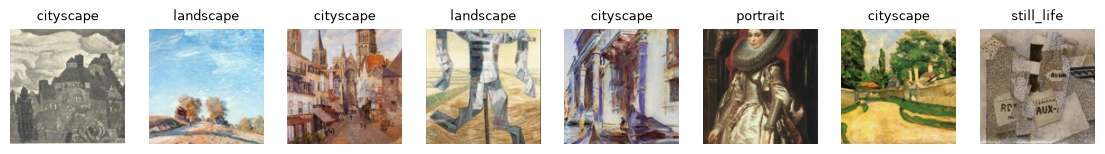

In [3]:
folder = datasets.ImageFolder(DATA_DIR)
CLASSES = folder.classes
images = np.stack([np.array(img) for img, _ in folder])          # (N, 128, 128, 3), uint8, values 0 to 255
X_full = torch.tensor(images).permute(0, 3, 1, 2).float() / 255  # (N, 3, 128, 128), pixels in [0, 1]
y_full = torch.tensor(folder.targets)                             # (N,), int64

print("X_full", tuple(X_full.shape), X_full.dtype, "| y_full", tuple(y_full.shape), y_full.dtype)
print("images per class:", dict(zip(CLASSES, torch.bincount(y_full).tolist())))

show = torch.randperm(len(y_full), generator=torch.Generator().manual_seed(0))[:8]
fig, axes = plt.subplots(1, 8, figsize=(14, 2.2))
for ax, k in zip(axes, show):
    ax.imshow(X_full[k].permute(1, 2, 0)); ax.set_title(CLASSES[y_full[k]], fontsize=9); ax.axis("off")
plt.show()

## Split train / validation / test, by artist

As in Session 4: train to compute the gradients, validation to choose, test measured once at the end, with a fixed
seed. One more rule from the production checklist of Session 8: **no artist on both sides**. Otherwise the network
can recognise the painter (Monet's brush) instead of the genre, and the test score is optimistic.

So we split **groups**, not images: all the paintings of a named artist go to the same set. "Unknown Artist" is a
catch-all of many painters, so each of its images is its own group. The groups are visited in a random order and a
group goes to test if it fits there (at most 1/6 of each class), else to validation, else to train: 1/6, 1/6 and 2/3
of each class, as with the digits of Session 4.

In [4]:
meta = pd.read_csv(os.path.join(DATA_DIR, "metadata.csv")).set_index("path")
artist = [meta.loc[os.path.relpath(p, DATA_DIR), "artist"] for p, _ in folder.samples]
# one group per named artist; "Unknown Artist" is a catch-all of many painters, so each of its images is its own group
group = [a if a != "Unknown Artist" else f"unknown_{i}" for i, a in enumerate(artist)]
names = sorted(set(group))
members = {g: [i for i, h in enumerate(group) if h == g] for g in names}

# groups in a random order: a group goes to test if it fits there (at most 1/6 of each class), else to validation,
# else to train. Classes stay balanced and an artist never appears in two sets.
order = torch.randperm(len(names), generator=torch.Generator().manual_seed(0)).tolist()
per_class = torch.bincount(y_full) // 6                         # 50 images of each class in test and in validation
filled = {"test": torch.zeros(len(CLASSES), dtype=torch.int64), "val": torch.zeros(len(CLASSES), dtype=torch.int64)}
split = {"train": [], "val": [], "test": []}
for k in order:
    idx = members[names[k]]
    counts = torch.bincount(y_full[idx], minlength=len(CLASSES))
    s = next((s for s in ["test", "val"] if (filled[s] + counts <= per_class).all()), "train")
    if s != "train":
        filled[s] += counts
    split[s] += idx
train_idx, val_idx, test_idx = (torch.tensor(sorted(split[s])) for s in ["train", "val", "test"])

X_train_raw, y_train = X_full[train_idx], y_full[train_idx]
X_val_raw, y_val = X_full[val_idx], y_full[val_idx]
X_test_raw, y_test = X_full[test_idx], y_full[test_idx]

named = {s: {artist[i] for i in split[s]} - {"Unknown Artist"} for s in split}
assert not (named["train"] & named["val"] or named["train"] & named["test"] or named["val"] & named["test"]), "an artist is on both sides"
print(f"train {len(train_idx)}, val {len(val_idx)}, test {len(test_idx)} | no named artist in two sets")
for s, y in [("train", y_train), ("val", y_val), ("test", y_test)]:
    print(f"{s:5s}", dict(zip(CLASSES, torch.bincount(y, minlength=len(CLASSES)).tolist())))

train 1000, val 250, test 250 | no named artist in two sets
train {'cityscape': 200, 'landscape': 200, 'portrait': 200, 'religious_painting': 200, 'still_life': 200}
val   {'cityscape': 50, 'landscape': 50, 'portrait': 50, 'religious_painting': 50, 'still_life': 50}
test  {'cityscape': 50, 'landscape': 50, 'portrait': 50, 'religious_painting': 50, 'still_life': 50}
